<a href="https://colab.research.google.com/github/makzjj/edge-face-recognition-dimensionality-reduction/blob/main/MakZhiJun_IE4476.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dimensionality Reduction for Face Identification on LFW
Closed-set identification among 62 people
(Labeled Faces in the Wild, at least 20 images each, 62×47 grayscale).

PCA, supervised PCA, PCA→LDA and SPCA→LDA are compared with three classifiers: 1. Minimum Mahalanobis
2. Regularised Mahalanobis
3. 1-NN.

Every learned parameter comes from training data only.

## 1. Configuration
Set `N_REPEATS = 2` for a quick run; the report uses 10.

In [ ]:
import os, io, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.linalg import eigh
from scipy.stats import binomtest, t as student_t
from scipy.ndimage import gaussian_filter

SEED       = 42
OUT_DIR    = "/content/drive/MyDrive/DR_assignment/figures_lfw"   # falls back to ./figures outside Colab

# Data (LFW, closed-set identification among people with enough images)
LFW_MIN_FACES = 20        # keep people with >= this many images (20 -> ~60 people; 70 -> only 7)
LFW_RESIZE    = 0.5       # 125x94 -> 62x47 = 2914 dims
PHOTO_NORM    = "zscore"  # per-image: "zscore" or "none"
SELECT_METRIC = "balanced"  # model selection score: "balanced" (mean per-person recall) or "accuracy"

# Protocol
TRAIN_FRAC = 0.5          # random split: fraction of each person's images used for training
N_REPEATS  = 10           # repeated random splits (paired differences, corrected resampled t-test)
VAL_FRAC   = 0.2          # fraction of TRAINING data held out for model selection
ETA_GRID   = [1.0, 0.25]                 # SPCA weight on class-mean covariance
M_GRID     = [50, 100, 200, 400]       # first-stage sizes tried before LDA
BASE_KS    = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50, 60, 80, 100,
              125, 150, 200, 250, 300, 400, 500, 600]
REG_GRID   = [1e-6, 0.01, 0.1, 1.0]       # shrinkage gamma for the regularised control
DEPLOY_TOL = 0.01         # deploy config: smallest k within 1 pt of best VALIDATION accuracy

# Camera degradation (applied to TEST images only, before normalisation): (name, blur sigma px, noise std on [0,1], JPEG quality)
DEG_LEVELS = [("clean", 0.0, 0.00, None), ("mild", 0.5, 0.02, 80), ("moderate", 1.0, 0.05, 50), ("severe", 1.5, 0.10, 25)]
DEG_REF_LEVEL = "moderate"

# RQ3
QUANT_BITS = [32, 16, 8, 6, 4]      # 32 = float32 reference
MCU = dict(name="STM32F446RE (Cortex-M4F)", clock_hz=180e6, flash_KB=512, ram_KB=128)
# ASSUMED cycles per MAC / per extra op (loads and flash wait states included). Illustrative only.
CYCLES_PER_MAC = {32: 3.0, 16: 1.5, 8: 1.5}    # 6- and 4-bit weights are unpacked and use the int8 path
CYCLES_PER_OP  = 2.0

np.random.seed(SEED)

## 2. Output folder (Google Drive is optional)

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: figures and CSVs go to ./figures")
    if OUT_DIR.startswith("/content"):
        OUT_DIR = "figures"
os.makedirs(OUT_DIR, exist_ok=True)
print("Output folder:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/DR_assignment/figures_lfw


## 3. Load and pre-process
LFW people with at least `LFW_MIN_FACES` images. Each image is z-score normalised using its own pixels only. Raw pixels are kept so test images can be degraded before normalisation (section 9b).

In [ ]:
from sklearn.datasets import fetch_lfw_people

lfw = fetch_lfw_people(min_faces_per_person=LFW_MIN_FACES, resize=LFW_RESIZE, funneled=True, color=False)
imgs = np.asarray(lfw.images, dtype=np.float64)
if imgs.max() > 1.5:                      # scikit-learn versions differ on the pixel range
    imgs = imgs / 255.0
assert imgs.min() >= -1e-6 and imgs.max() <= 1.0 + 1e-6, "unexpected pixel range"
IMG_H, IMG_W = imgs.shape[1:]
X_raw = imgs.reshape(len(imgs), -1)
names, y = np.unique(lfw.target_names[lfw.target], return_inverse=True)

def prep(Xr):
    if PHOTO_NORM != "zscore":
        return Xr.copy()
    return (Xr - Xr.mean(axis=1, keepdims=True)) / (Xr.std(axis=1, keepdims=True) + 1e-8)

X = prep(X_raw)
C, D = len(names), X.shape[1]
print(f"{len(y)} images, {C} people, {D} dims ({IMG_H}x{IMG_W})")

3023 images, 62 people, 2914 dims (62x47)


In [ ]:
def stratified_split(labels, train_frac, seed):
    rng = np.random.default_rng(seed)
    tr, te = [], []
    for c in np.unique(labels):
        idx = np.flatnonzero(labels == c)
        rng.shuffle(idx)
        n = min(max(int(round(train_frac * len(idx))), 1), len(idx) - 1)   # at least one image on each side
        tr.extend(idx[:n]); te.extend(idx[n:])
    return np.array(sorted(tr)), np.array(sorted(te))


### Pre-flight checks

In [ ]:
per_p = pd.Series(y).value_counts()
share = per_p / per_p.sum()
print(f"People: {C}" + ("   <-- WARNING: very few classes; lower LFW_MIN_FACES" if C < 15 else "")
      + ("   <-- WARNING: many classes; runtime grows, consider raising LFW_MIN_FACES" if C > 200 else ""))
print(f"Images per person: min {per_p.min()}, median {int(per_p.median())}, max {per_p.max()}, total {len(y)}")
print("Largest classes:", {names[i]: int(n) for i, n in per_p.head(3).items()})
print(f"Chance baselines: majority-class accuracy {100*share.max():.1f}%, uniform guess {100/C:.1f}% (balanced chance {100/C:.1f}%)")
_tr, _ = stratified_split(y, TRAIN_FRAC, SEED)
tr_per = pd.Series(y[_tr]).value_counts()
val_per = (tr_per * VAL_FRAC).round()
print(f"Split 1 training images per person: min {tr_per.min()} (≈{int(val_per.min())} for validation)")
assert tr_per.min() >= 3, "each person needs at least 3 training images"
assert val_per.min() >= 1, "validation split needs at least 1 image per person"

People: 62
Images per person: min 20, median 31, max 530, total 3023
Largest classes: {np.str_('George W Bush'): 530, np.str_('Colin Powell'): 236, np.str_('Tony Blair'): 144}
Chance baselines: majority-class accuracy 17.5%, uniform guess 1.6% (balanced chance 1.6%)
Split 1 training images per person: min 10 (≈2 for validation)


## 4. Dimensionality reduction (from scratch)
* **PCA:** SVD of the centred training matrix.
* **SPCA:** eigenvectors of $\sum_i\alpha_i S_i+\eta S_m$. Default $\alpha_i=1/C$ (class-balanced); $\alpha_i=q_i/q$ is size-weighted, and with $\eta=1$ it equals PCA (checked below).
* **LDA:** generalised eigenproblem $S_b w=\lambda S_w w$, at most $C-1$ directions.

In [ ]:
class PCA:
    def fit(self, X, y=None):
        self.mean_ = X.mean(axis=0)
        _, S, Vt = np.linalg.svd(X - self.mean_, full_matrices=False)
        self.components_, self.eigenvalues_ = Vt, S**2 / (len(X) - 1)
        return self

class SPCA:
    def __init__(self, eta=0.25, alpha="equal"):
        self.eta, self.alpha = eta, alpha
    def fit(self, X, y):
        classes = np.unique(y); Cn, q = len(classes), len(X)
        self.mean_ = X.mean(axis=0)
        blocks = []
        for c in classes:
            Xc = X[y == c]; qc = len(Xc); mc = Xc.mean(axis=0)
            a = 1.0 / Cn if self.alpha == "equal" else qc / q
            blocks.append(np.sqrt(a / qc) * (Xc - mc))                            # alpha_i S_i
            blocks.append(np.sqrt(self.eta * qc / q) * (mc - self.mean_)[None, :])  # eta S_m
        _, S, Vt = np.linalg.svd(np.vstack(blocks), full_matrices=False)
        self.components_, self.eigenvalues_ = Vt, S**2
        return self

class LDA:
    def fit(self, Z, y, reg=1e-4):
        classes = np.unique(y); mu = Z.mean(axis=0); d = Z.shape[1]
        Sw = np.zeros((d, d)); Sb = np.zeros((d, d))
        for c in classes:
            Zc = Z[y == c]; mc = Zc.mean(axis=0); Dc = Zc - mc
            Sw += Dc.T @ Dc
            diff = (mc - mu)[:, None]; Sb += len(Zc) * (diff @ diff.T)
        Sw += reg * np.trace(Sw) / d * np.eye(d)
        evals, evecs = eigh(Sb, Sw)
        order = np.argsort(evals)[::-1][: min(len(classes) - 1, d)]
        self.W_, self.evals_ = evecs[:, order], evals[order]
        return self

# Sanity check: SPCA(alpha = q_i/q, eta = 1) must give the same directions as PCA.
_tr, _ = stratified_split(y, TRAIN_FRAC, SEED)
_p, _s = PCA().fit(X[_tr]), SPCA(eta=1.0, alpha="prior").fit(X[_tr], y[_tr])
_cos = np.abs(np.sum(_p.components_[:10] * _s.components_[:10], axis=1))
print("|cos| of top-10 PCA vs SPCA(eta=1, alpha=q_i/q) components:", np.round(_cos, 4))
assert np.all(_cos > 0.999), "SPCA special case does not reproduce PCA"

|cos| of top-10 PCA vs SPCA(eta=1, alpha=q_i/q) components: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Classifiers
Mahalanobis (pooled within-class covariance, near-zero ridge); Mahalanobis-reg (shrinkage γ chosen on validation); 1-NN (Euclidean).

In [ ]:
def sqdist(A, B):
    return (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2.0 * A @ B.T

class MinMahalanobis:
    def __init__(self, reg=1e-6):
        self.reg = reg
    def fit(self, Z, y):
        self.classes_ = np.unique(y)
        self.means_ = np.stack([Z[y == c].mean(axis=0) for c in self.classes_])
        Dz = Z - self.means_[np.searchsorted(self.classes_, y)]
        k = Z.shape[1]
        S = Dz.T @ Dz / max(len(Z) - len(self.classes_), 1)
        S += self.reg * np.trace(S) / k * np.eye(k)
        self.Linv_ = np.linalg.inv(np.linalg.cholesky(S))
        self.wmeans_ = self.means_ @ self.Linv_.T
        return self
    def predict(self, Z):
        return self.classes_[sqdist(Z @ self.Linv_.T, self.wmeans_).argmin(axis=1)]

class NearestNeighbour:
    def fit(self, Z, y):
        self.Z_, self.y_ = Z, y
        return self
    def predict(self, Z):
        return self.y_[sqdist(Z, self.Z_).argmin(axis=1)]

CLF_NAMES = ["Mahalanobis", "Mahalanobis-reg", "1-NN"]
def classifier_factories(gamma):
    return {"Mahalanobis": lambda: MinMahalanobis(1e-6),
            "Mahalanobis-reg": lambda: MinMahalanobis(gamma),
            "1-NN": lambda: NearestNeighbour()}

## 6. Pipelines as one linear map, and the resource model
Every pipeline folds into one $D\times k$ matrix, a bias and a nearest-template search. Flash = weights (+ scales, bias, templates); RAM = input buffer + $z$; operations = $Dk$ + templates·$k$. Latency is estimated from assumed cycles per operation, not measured.

In [ ]:
METHODS = ["PCA", "SPCA", "PCA→LDA", "SPCA→LDA"]

def fit_base(method, X_, y_, eta, alpha="equal"):
    return SPCA(eta=eta, alpha=alpha).fit(X_, y_) if method.startswith("SPCA") else PCA().fit(X_)

def balanced_accuracy(y_true, y_pred):
    return float(np.mean([np.mean(y_pred[y_true == c] == c) for c in np.unique(y_true)]))

def select_score(y_true, y_pred):
    return balanced_accuracy(y_true, y_pred) if SELECT_METRIC == "balanced" else float((y_true == y_pred).mean())

def fit_map(method, X_, y_, eta=None, m=None, base=None, alpha="equal"):
    base = base if base is not None else fit_base(method, X_, y_, eta, alpha)
    if "LDA" not in method:
        return base.mean_, base.components_.T
    P = base.components_[:m].T
    lda = LDA().fit((X_ - base.mean_) @ P, y_)
    return base.mean_, P @ lda.W_

def k_grid(method, n_train, n_classes):
    if "LDA" in method:
        return list(range(1, n_classes))
    return [k for k in BASE_KS if k <= min(n_train - n_classes, D)]

def predict_curve(mu, B, Xa, ya, Xb, ks, factories):
    Za, Zb = (Xa - mu) @ B[:, :max(ks)], (Xb - mu) @ B[:, :max(ks)]
    return {(name, k): make().fit(Za[:, :k], ya).predict(Zb[:, :k])
            for name, make in factories.items() for k in ks}

def deploy_cost(k, n_classes, n_train, clf, bits=32):
    n_tmpl = n_classes if clf.startswith("Mahalanobis") else n_train
    integer = bits < 32
    flash = D * k * bits / 8 + (4 * k if integer else 0) + 4 * k + 4 * n_tmpl * k
    ram = 4 * D + (D * bits / 8 if integer else 0) + 4 * k + 64
    macs = D * k + n_tmpl * k
    extra = 2 * D if integer else 0
    cyc = macs * CYCLES_PER_MAC.get(bits, CYCLES_PER_MAC[8]) + extra * CYCLES_PER_OP
    return dict(flash_KB=flash / 1024, ram_KB=ram / 1024, ops=macs + extra,
                est_latency_ms=1e3 * cyc / MCU["clock_hz"])

## 7. Model selection (training data only)
Every candidate is scored on a validation split of the training data (balanced accuracy).
* **Shared basis (RQ1):** $\eta, m$ are chosen with plain Mahalanobis; the other classifiers reuse that basis and choose their own $k$ and γ.
* **Independent (RQ3):** each classifier selects $(\eta, m, \gamma, k)$ itself. The deploy $k$ is the smallest $k$ within `DEPLOY_TOL` of the best validation score.

In [ ]:
def choose_deploy(recs, tol):          # recs: (eta, m, gamma, k, val_acc)
    top = max(r[4] for r in recs)
    return min((r for r in recs if r[4] >= top - tol), key=lambda r: (r[3], -r[4]))

def choose_accopt(recs):
    top = max(r[4] for r in recs)
    return min((r for r in recs if r[4] == top), key=lambda r: r[3])

def select_hparams(Xtr_, ytr_, seed, alpha="equal", methods=None):
    methods = methods or METHODS
    Cn = len(np.unique(ytr_))
    s_tr, s_val = stratified_split(ytr_, 1 - VAL_FRAC, seed + 1)
    Xs, ys, Xv, yv = Xtr_[s_tr], ytr_[s_tr], Xtr_[s_val], ytr_[s_val]
    m_cap = len(ys) - Cn
    m_grid = sorted({m for m in M_GRID if Cn <= m <= m_cap}) or [m_cap]   # m_cap only as a fallback for small datasets
    acc = lambda p: select_score(yv, p)
    facts = {"Mahalanobis": lambda: MinMahalanobis(1e-6), "1-NN": lambda: NearestNeighbour()}
    facts.update({("reg", g): (lambda g=g: MinMahalanobis(g)) for g in REG_GRID})
    hp = {}
    for method in methods:
        two = "LDA" in method
        etas = ETA_GRID if method.startswith("SPCA") else [None]
        ms = m_grid if two else [None]
        ks = list(range(1, Cn)) if two else k_grid(method, len(ys), Cn)
        recs = {"Mahalanobis": [], "Mahalanobis-reg": [], "1-NN": []}
        for eta in etas:
            base = fit_base(method, Xs, ys, eta, alpha)
            for m in ms:
                mu, B = fit_map(method, Xs, ys, m=m, base=base, alpha=alpha)
                p = predict_curve(mu, B, Xs, ys, Xv, ks, facts)
                for k in ks:
                    recs["Mahalanobis"].append((eta, m, None, k, acc(p[("Mahalanobis", k)])))
                    recs["1-NN"].append((eta, m, None, k, acc(p[("1-NN", k)])))
                    for g in REG_GRID:
                        recs["Mahalanobis-reg"].append((eta, m, g, k, acc(p[(("reg", g), k)])))
        # ---- shared-representation mode ----
        eta, m, _, k_dep, _ = choose_deploy(recs["Mahalanobis"], DEPLOY_TOL)
        same = lambda r: r[0] == eta and r[1] == m
        reg_same = [r for r in recs["Mahalanobis-reg"] if same(r)]
        gamma = max(REG_GRID, key=lambda g: max(r[4] for r in reg_same if r[2] == g))
        curves = {"Mahalanobis": [r for r in recs["Mahalanobis"] if same(r)],
                  "Mahalanobis-reg": [r for r in reg_same if r[2] == gamma],
                  "1-NN": [r for r in recs["1-NN"] if same(r)]}
        deploy_k = {c: choose_deploy(v, DEPLOY_TOL)[3] for c, v in curves.items()}
        deploy_k["Mahalanobis"] = k_dep
        accopt_k = {c: choose_accopt(v)[3] for c, v in curves.items()}
        # ---- independent mode ----
        indep = {c: dict(deploy=choose_deploy(v, DEPLOY_TOL), acc=choose_accopt(v)) for c, v in recs.items()}
        hp[method] = dict(eta=eta, m=m, gamma=gamma, deploy_k=deploy_k, accopt_k=accopt_k,
                          records=recs, indep=indep,
                          saturation=float(np.mean([r[4] >= max(x[4] for x in recs["Mahalanobis"]) - DEPLOY_TOL
                                                    for r in recs["Mahalanobis"]])))
    return hp

def make_clf(clf, gamma):
    return NearestNeighbour() if clf == "1-NN" else MinMahalanobis(gamma if clf == "Mahalanobis-reg" else 1e-6)

def run_experiment(Xtr_, ytr_, Xte_, yte_, seed, tag, alpha="equal", methods=None):
    methods = methods or METHODS
    Cn = len(np.unique(ytr_))
    hp = select_hparams(Xtr_, ytr_, seed, alpha, methods)
    rows, preds_all, maps, indep_rows = [], {}, {}, []
    map_cache = {}
    def get_map(method, eta, m):
        if (method, eta, m) not in map_cache:
            map_cache[(method, eta, m)] = fit_map(method, Xtr_, ytr_, eta=eta, m=m, alpha=alpha)
        return map_cache[(method, eta, m)]
    for method in methods:
        h = hp[method]
        mu, B = get_map(method, h["eta"], h["m"])
        maps[method] = (mu, B)
        preds = predict_curve(mu, B, Xtr_, ytr_, Xte_, k_grid(method, len(ytr_), Cn),
                              classifier_factories(h["gamma"]))
        preds_all[method] = preds
        for (clf, k), p in preds.items():
            a = float((p == yte_).mean()); ba = balanced_accuracy(yte_, p)
            rows.append(dict(split=tag, seed=seed, method=method, classifier=clf, k=k,
                             accuracy=a, error=1 - a, bal_accuracy=ba, bal_error=1 - ba,
                             is_deploy=(k == h["deploy_k"][clf]), is_accopt=(k == h["accopt_k"][clf]),
                             **deploy_cost(k, Cn, len(ytr_), clf)))
        for clf in CLF_NAMES:
            for which in ["deploy", "acc"]:
                eta, m, g, k, v = h["indep"][clf][which]
                mu_, B_ = get_map(method, eta, m)
                p = make_clf(clf, g).fit((Xtr_ - mu_) @ B_[:, :k], ytr_).predict((Xte_ - mu_) @ B_[:, :k])
                indep_rows.append(dict(split=tag, seed=seed, method=method, classifier=clf, which=which,
                                       eta=eta, m=m, gamma=g, k=k, val_acc=v,
                                       test_acc=float((p == yte_).mean()), test_bal_acc=balanced_accuracy(yte_, p),
                                       **deploy_cost(k, Cn, len(ytr_), clf)))
    return pd.DataFrame(rows), hp, preds_all, maps, pd.DataFrame(indep_rows)

## 8. RQ1: error vs dimensionality
Ten stratified 50/50 splits, all hyperparameters reselected inside each split. Pairwise differences use the corrected resampled t-test (Nadeau and Bengio); McNemar is applied once, on split 1. All tests are exploratory.

In [ ]:
t0 = time.time()
rep_results, rep_hp, rep_indep = [], [], []
rep_results_w, rep_hp_w = [], []      # size-weighted SPCA (alpha_i = q_i/q), section 8b
for r in range(N_REPEATS):
    seed = SEED + r
    tr, te = stratified_split(y, TRAIN_FRAC, seed)
    res, hp, preds, maps, ind = run_experiment(X[tr], y[tr], X[te], y[te], seed, "random")
    rep_results.append(res); rep_hp.append(hp); rep_indep.append(ind)
    resw, hpw, _, _, _ = run_experiment(X[tr], y[tr], X[te], y[te], seed, "random", alpha="prior", methods=["SPCA"])
    rep_results_w.append(resw); rep_hp_w.append(hpw)
    if r == 0:
        TR0, TE0, HP0, MAPS0, PREDS0 = tr, te, hp, maps, preds
    print(f"repeat {r+1}/{N_REPEATS} done ({time.time()-t0:.0f}s)")
random_results = pd.concat(rep_results, ignore_index=True)
random_results.to_csv(os.path.join(OUT_DIR, "rq1_random_results.csv"), index=False)
random_results_w = pd.concat(rep_results_w, ignore_index=True)
random_results_w.to_csv(os.path.join(OUT_DIR, "rq1_random_results_sizeweighted_spca.csv"), index=False)
indep_results = pd.concat(rep_indep, ignore_index=True)
indep_results.to_csv(os.path.join(OUT_DIR, "rq3_independent_selection.csv"), index=False)
Xtr0, ytr0, Xte0, yte0 = X[TR0], y[TR0], X[TE0], y[TE0]
N_TR, N_TE = len(TR0), len(TE0)

hp_table = pd.DataFrame([{"seed": SEED + r,
                          **{f"{m} η": h[m]["eta"] for m in ["SPCA", "SPCA→LDA"]},
                          **{f"{m} m": h[m]["m"] for m in ["PCA→LDA", "SPCA→LDA"]},
                          **{f"{m} k": h[m]["deploy_k"]["Mahalanobis"] for m in METHODS},
                          **{f"{m} γ": h[m]["gamma"] for m in METHODS}}
                         for r, h in enumerate(rep_hp)])
print("Shared-representation configurations chosen on training data, per repeat:"); display(hp_table)
print("Fraction of plain-Mahalanobis validation candidates within tolerance of the top (saturation):")
display(pd.DataFrame([{m: round(h[m]["saturation"], 3) for m in METHODS} for h in rep_hp]))
g_ind = indep_results[(indep_results.classifier == "Mahalanobis-reg") & (indep_results.which == "deploy")].gamma
print("γ chosen (independent, Mahalanobis-reg):", g_ind.value_counts().to_dict(),
      "| at grid edge:", int(g_ind.isin([REG_GRID[0], REG_GRID[-1]]).sum()), "of", len(g_ind))
for col in ["SPCA η", "SPCA→LDA η"]:
    print(f"How often each η was chosen ({col}):", hp_table[col].value_counts().to_dict())

repeat 1/10 done (123s)
repeat 2/10 done (259s)
repeat 3/10 done (379s)
repeat 4/10 done (507s)
repeat 5/10 done (631s)
repeat 6/10 done (769s)
repeat 7/10 done (897s)
repeat 8/10 done (1018s)
repeat 9/10 done (1133s)
repeat 10/10 done (1255s)
Shared-representation configurations chosen on training data, per repeat:


,seed,SPCA η,SPCA→LDA η,PCA→LDA m,SPCA→LDA m,PCA k,SPCA k,PCA→LDA k,SPCA→LDA k,PCA γ,SPCA γ,PCA→LDA γ,SPCA→LDA γ
0,42,1.00,0.25,100,100,150,125,17,20,0.100000,0.100000,0.000001,0.000001
1,43,1.00,0.25,100,100,125,125,25,25,0.000001,0.000001,0.000001,0.000001
2,44,0.25,0.25,100,200,125,80,21,44,0.100000,0.100000,0.000001,0.000001
3,45,1.00,0.25,100,200,60,125,20,40,1.000000,1.000000,0.000001,0.000001
4,46,1.00,1.00,100,100,40,100,31,45,1.000000,0.000001,0.000001,0.000001
5,47,0.25,1.00,100,200,100,80,20,22,1.000000,1.000000,0.000001,0.000001
6,48,1.00,0.25,100,100,100,60,22,19,0.100000,0.100000,0.000001,0.000001
7,49,1.00,0.25,100,100,80,80,43,24,0.100000,0.100000,0.000001,0.000001
8,50,1.00,1.00,100,100,60,60,18,33,0.100000,0.100000,0.000001,0.000001
9,51,0.25,1.00,100,100,100,60,28,32,0.100000,0.010000,0.000001,0.000001


Fraction of plain-Mahalanobis validation candidates within tolerance of the top (saturation):


,PCA,SPCA,PCA→LDA,SPCA→LDA
0,0.045,0.068,0.033,0.019
1,0.045,0.023,0.049,0.008
2,0.091,0.114,0.044,0.019
3,0.182,0.091,0.033,0.011
4,0.182,0.023,0.027,0.011
5,0.045,0.045,0.082,0.011
6,0.091,0.114,0.027,0.014
7,0.045,0.045,0.011,0.038
8,0.182,0.068,0.049,0.038
9,0.091,0.045,0.027,0.022


γ chosen (independent, Mahalanobis-reg): {1e-06: 23, 0.1: 13, 1.0: 3, 0.01: 1} | at grid edge: 26 of 40
How often each η was chosen (SPCA η): {1.0: 7, 0.25: 3}
How often each η was chosen (SPCA→LDA η): {0.25: 6, 1.0: 4}


In [ ]:
COMPARISONS = [("SPCA", "Mahalanobis", "PCA", "Mahalanobis"),
               ("SPCA→LDA", "Mahalanobis", "PCA→LDA", "Mahalanobis"),
               ("PCA", "Mahalanobis-reg", "PCA", "Mahalanobis"),
               ("SPCA", "Mahalanobis-reg", "PCA", "Mahalanobis-reg"),
               ("SPCA→LDA", "Mahalanobis-reg", "PCA→LDA", "Mahalanobis-reg")]

def deploy_acc(df, method, clf, col="accuracy"):
    d = df[(df.method == method) & (df.classifier == clf) & df.is_deploy]
    return d.groupby("seed")[col].first()

def corrected_resampled_t(diffs, n_train, n_test):
    J = len(diffs); mean = diffs.mean(); var = diffs.var(ddof=1)
    if J < 2 or var == 0:
        return np.nan
    t = mean / np.sqrt((1 / J + n_test / n_train) * var)
    return 2 * student_t.sf(abs(t), J - 1)

def mcnemar(correct_a, correct_b):
    b = int(np.sum(correct_a & ~correct_b)); c = int(np.sum(~correct_a & correct_b))
    return b, c, (binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0)

stat_rows = []
for ma, ca, mb, cb in COMPARISONS:
    for metric, col in [("accuracy", "accuracy"), ("balanced accuracy", "bal_accuracy")]:
        a, b = deploy_acc(random_results, ma, ca, col), deploy_acc(random_results, mb, cb, col)
        diffs = (a - b).values
        row = {"comparison": f"{ma}+{ca}  vs  {mb}+{cb}", "metric": metric,
               "mean diff (pts)": round(100 * diffs.mean(), 2),
               "std diff (pts)": round(100 * diffs.std(ddof=1), 2) if len(diffs) > 1 else np.nan,
               "corrected t-test p": corrected_resampled_t(diffs, N_TR, N_TE)}
        if metric == "accuracy":     # McNemar applies to per-image correctness: first split only
            ka, kb = HP0[ma]["deploy_k"][ca], HP0[mb]["deploy_k"][cb]
            nb_, nc_, p_mc = mcnemar(PREDS0[ma][(ca, ka)] == yte0, PREDS0[mb][(cb, kb)] == yte0)
            row["McNemar split 1: only A / only B correct"] = f"{nb_} / {nc_}"; row["McNemar split 1 p"] = p_mc
        stat_rows.append(row)
stats_table = pd.DataFrame(stat_rows)
stats_table.to_csv(os.path.join(OUT_DIR, "rq1_statistics.csv"), index=False)
display(stats_table)

,comparison,metric,mean diff (pts),std diff (pts),corrected t-test p,McNemar split 1: only A / only B correct,McNemar split 1 p
0,SPCA+Mahalanobis vs PCA+Mahalanobis,accuracy,0.32,5.26,0.954597,65 / 52,0.267182
1,SPCA+Mahalanobis vs PCA+Mahalanobis,balanced accuracy,0.36,3.67,0.928102,NaN,NaN
2,SPCA→LDA+Mahalanobis vs PCA→LDA+Mahalanobis,accuracy,0.65,2.10,0.774269,79 / 80,1.000000
3,SPCA→LDA+Mahalanobis vs PCA→LDA+Mahalanobis,balanced accuracy,-0.12,1.08,0.920044,NaN,NaN
4,PCA+Mahalanobis-reg vs PCA+Mahalanobis,accuracy,2.23,4.17,0.623057,74 / 48,0.023216
5,PCA+Mahalanobis-reg vs PCA+Mahalanobis,balanced accuracy,1.77,2.63,0.538915,NaN,NaN
6,SPCA+Mahalanobis-reg vs PCA+Mahalanobis-reg,accuracy,-1.65,4.22,0.718627,29 / 38,0.328432
7,SPCA+Mahalanobis-reg vs PCA+Mahalanobis-reg,balanced accuracy,-1.17,2.33,0.645370,NaN,NaN
8,SPCA→LDA+Mahalanobis-reg vs PCA→LDA+Mahalano...,accuracy,0.78,2.10,0.731758,68 / 71,0.865374
9,SPCA→LDA+Mahalanobis-reg vs PCA→LDA+Mahalano...,balanced accuracy,-0.12,1.24,0.927940,NaN,NaN


In [ ]:
# Unreduced baseline: 1-NN on the full 2,914 raw (normalised) pixels, same splits. (Mahalanobis on raw pixels is singular, so it is not used.)
base_rows = []
for r in range(N_REPEATS):
    tr_, te_ = stratified_split(y, TRAIN_FRAC, SEED + r)
    p = NearestNeighbour().fit(X[tr_], y[tr_]).predict(X[te_])
    base_rows.append(dict(seed=SEED + r, accuracy=float((p == y[te_]).mean()), bal_accuracy=balanced_accuracy(y[te_], p)))
base_df = pd.DataFrame(base_rows)
BASE_ERR, BASE_BAL_ERR = 1 - base_df.accuracy.mean(), 1 - base_df.bal_accuracy.mean()
cmp_rows = []
for method in METHODS:
    for col, lab in [("accuracy", "accuracy"), ("bal_accuracy", "balanced accuracy")]:
        red = deploy_acc(random_results, method, "1-NN", col)
        diffs = (red - base_df.set_index("seed")[col]).values
        cmp_rows.append({"reduced 1-NN vs raw-pixel 1-NN": method, "metric": lab,
                         "raw pixels (%)": round(100 * base_df[col].mean(), 2), "reduced, deploy k (%)": round(100 * red.mean(), 2),
                         "mean diff (pts)": round(100 * diffs.mean(), 2),
                         "corrected t-test p": corrected_resampled_t(diffs, N_TR, N_TE)})
baseline_table = pd.DataFrame(cmp_rows)
baseline_table.to_csv(os.path.join(OUT_DIR, "rq1_unreduced_baseline.csv"), index=False)
print(f"Unreduced raw-pixel 1-NN (D = {D}): accuracy {100*base_df.accuracy.mean():.1f}%, balanced accuracy {100*base_df.bal_accuracy.mean():.1f}%")
display(baseline_table)

Unreduced raw-pixel 1-NN (D = 2914): accuracy 37.1%, balanced accuracy 27.4%


,reduced 1-NN vs raw-pixel 1-NN,metric,raw pixels (%),"reduced, deploy k (%)",mean diff (pts),corrected t-test p
0,PCA,accuracy,37.10,36.10,-1.00,3.859900e-01
1,PCA,balanced accuracy,27.42,26.96,-0.46,6.347239e-01
2,SPCA,accuracy,37.10,36.38,-0.73,6.586906e-01
3,SPCA,balanced accuracy,27.42,26.02,-1.40,2.716760e-01
4,PCA→LDA,accuracy,37.10,50.94,13.84,5.928159e-07
5,PCA→LDA,balanced accuracy,27.42,38.95,11.54,5.669609e-05
6,SPCA→LDA,accuracy,37.10,50.51,13.41,9.476269e-04
7,SPCA→LDA,balanced accuracy,27.42,37.95,10.54,3.781990e-03


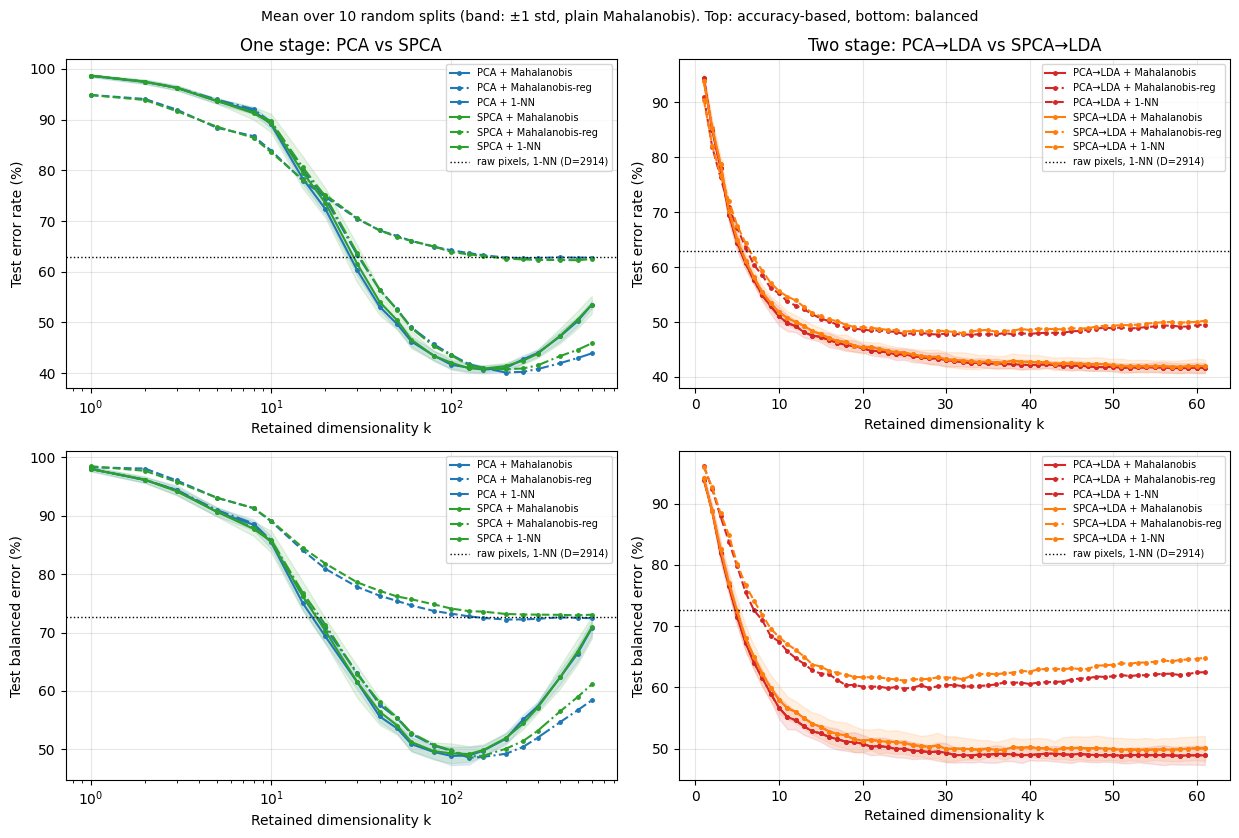

In [ ]:
COLORS = {"PCA": "tab:blue", "SPCA": "tab:green", "PCA→LDA": "tab:red", "SPCA→LDA": "tab:orange"}
LINES  = {"Mahalanobis": "-", "Mahalanobis-reg": "-.", "1-NN": "--"}

def mean_curve(df, method, clf, col="error"):
    g = df[(df.method == method) & (df.classifier == clf)].groupby("k")
    return g[col].mean(), g[col].std().fillna(0)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5))
for row, (col, ylab) in enumerate([("error", "Test error rate (%)"), ("bal_error", "Test balanced error (%)")]):
    for ax, methods in zip(axes[row], [["PCA", "SPCA"], ["PCA→LDA", "SPCA→LDA"]]):
        for method in methods:
            for clf in CLF_NAMES:
                e, s = mean_curve(random_results, method, clf, col)
                ax.plot(e.index, 100 * e, LINES[clf], color=COLORS[method], marker="o", ms=2.5,
                        label=f"{method} + {clf}")
                if clf == "Mahalanobis":
                    ax.fill_between(e.index, 100 * (e - s), 100 * (e + s), color=COLORS[method], alpha=0.12)
        ax.axhline(100 * (BASE_ERR if col == "error" else BASE_BAL_ERR), color="black", ls=":", lw=1, label=f"raw pixels, 1-NN (D={D})")
        ax.set_xlabel("Retained dimensionality k"); ax.set_ylabel(ylab)
        ax.grid(alpha=0.3); ax.legend(fontsize=7)
    axes[row, 0].set_xscale("log")
axes[0, 0].set_title("One stage: PCA vs SPCA"); axes[0, 1].set_title("Two stage: PCA→LDA vs SPCA→LDA")
fig.suptitle(f"Mean over {N_REPEATS} random splits (band: ±1 std, plain Mahalanobis). Top: accuracy-based, bottom: balanced", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_error_vs_k.png"), dpi=300); plt.show()

## 8b. Class-balanced vs size-weighted SPCA
Same splits and selection protocol; paired differences.

In [ ]:
wt_rows = []
for clf in ["Mahalanobis", "Mahalanobis-reg"]:
    for metric, col in [("accuracy", "accuracy"), ("balanced accuracy", "bal_accuracy")]:
        a = deploy_acc(random_results, "SPCA", clf, col)            # class-balanced alpha_i = 1/C
        b = deploy_acc(random_results_w, "SPCA", clf, col)          # size-weighted alpha_i = q_i/q
        diffs = (a - b).values
        wt_rows.append({"classifier": clf, "metric": metric,
                        "class-balanced (%)": round(100 * a.mean(), 2), "size-weighted (%)": round(100 * b.mean(), 2),
                        "mean diff (pts)": round(100 * diffs.mean(), 2),
                        "std diff (pts)": round(100 * diffs.std(ddof=1), 2) if len(diffs) > 1 else np.nan,
                        "corrected t-test p": corrected_resampled_t(diffs, N_TR, N_TE)})
weight_table = pd.DataFrame(wt_rows)
weight_table.to_csv(os.path.join(OUT_DIR, "rq1_spca_weighting.csv"), index=False)
display(weight_table)
eta_w = pd.Series([h["SPCA"]["eta"] for h in rep_hp_w]); eta_e = pd.Series([h["SPCA"]["eta"] for h in rep_hp])
print("η chosen, class-balanced SPCA:", eta_e.value_counts().to_dict())
print("η chosen, size-weighted SPCA :", eta_w.value_counts().to_dict(),
      f"  (η = 1 means the size-weighted model chose plain PCA: {int((eta_w == 1.0).sum())} of {len(eta_w)})")
print("Training images per person, split 1: min", int(tr_per.min()), "median", int(tr_per.median()), "max", int(tr_per.max()))

,classifier,metric,class-balanced (%),size-weighted (%),mean diff (pts),std diff (pts),corrected t-test p
0,Mahalanobis,accuracy,56.67,57.11,-0.44,3.85,0.915271
1,Mahalanobis,balanced accuracy,49.90,50.12,-0.22,2.54,0.936838
2,Mahalanobis-reg,accuracy,56.92,58.01,-1.08,4.25,0.813943
3,Mahalanobis-reg,balanced accuracy,50.14,50.94,-0.80,2.49,0.767638


η chosen, class-balanced SPCA: {1.0: 7, 0.25: 3}
η chosen, size-weighted SPCA : {1.0: 7, 0.25: 3}   (η = 1 means the size-weighted model chose plain PCA: 7 of 10)
Training images per person, split 1: min 10 median 16 max 265


## 9. Reliability and robustness
### 9a. Held-out vs training variance (training data only)
Along the within-class eigen-directions, compare the training eigenvalue λ with the held-out within-class variance $v$ and the class-centroid shift $c$. Ratios above 1 mean the training data underestimate that direction. This is a diagnostic, not a formal test.

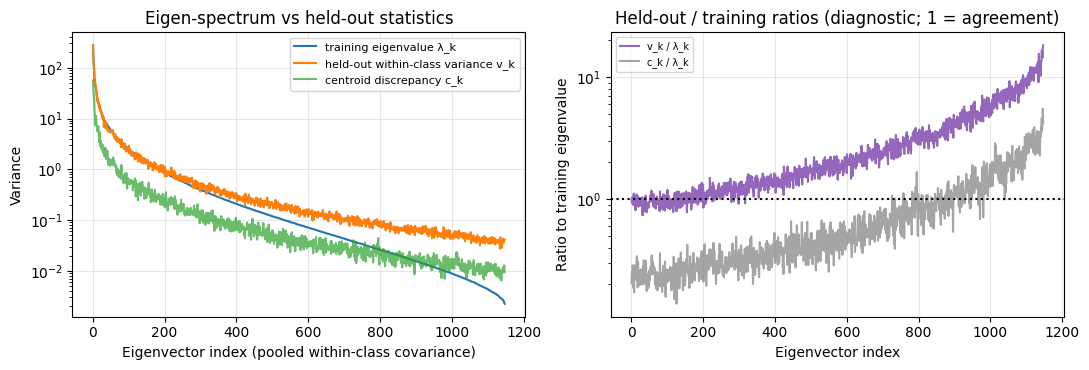

Median v/λ: first quarter 1.02, last quarter 6.06
Median c/λ: first quarter 0.26, last quarter 1.60


In [ ]:
def within_class_reliability(Xs, ys, Xv, yv):
    classes = np.unique(ys)
    mu_s = {c: Xs[ys == c].mean(axis=0) for c in classes}
    _, S, Vt = np.linalg.svd(np.vstack([Xs[ys == c] - mu_s[c] for c in classes]), full_matrices=False)
    lam = S**2 / (len(Xs) - len(classes))
    keep = lam > 1e-10 * lam[0]
    lam, Vt = lam[keep], Vt[keep]
    vc = [c for c in classes if np.sum(yv == c) >= 2]
    mu_v = {c: Xv[yv == c].mean(axis=0) for c in vc}
    Dv = np.vstack([Xv[yv == c] - mu_v[c] for c in vc])
    v_within = ((Dv @ Vt.T) ** 2).sum(axis=0) / (len(Dv) - len(vc))
    w = np.array([np.sum(yv == c) for c in vc], dtype=float)
    shifts = np.stack([(mu_v[c] - mu_s[c]) @ Vt.T for c in vc]) ** 2
    c_disc = (w[:, None] * shifts).sum(axis=0) / w.sum()
    return lam, v_within, c_disc

s_tr, s_val = stratified_split(ytr0, 1 - VAL_FRAC, SEED + 1)
lam, v_w, c_d = within_class_reliability(Xtr0[s_tr], ytr0[s_tr], Xtr0[s_val], ytr0[s_val])
idx = np.arange(1, len(lam) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(idx, lam, label="training eigenvalue λ_k")
axes[0].semilogy(idx, v_w, label="held-out within-class variance v_k")
axes[0].semilogy(idx, c_d, label="centroid discrepancy c_k", alpha=0.7)
axes[0].set_xlabel("Eigenvector index (pooled within-class covariance)"); axes[0].set_ylabel("Variance")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3); axes[0].set_title("Eigen-spectrum vs held-out statistics")
axes[1].semilogy(idx, v_w / lam, color="tab:purple", label="v_k / λ_k")
axes[1].semilogy(idx, c_d / lam, color="tab:gray", alpha=0.7, label="c_k / λ_k")
axes[1].axhline(1, ls=":", color="black")
axes[1].set_xlabel("Eigenvector index"); axes[1].set_ylabel("Ratio to training eigenvalue")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
axes[1].set_title("Held-out / training ratios (diagnostic; 1 = agreement)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_eigenvalue_reliability.png"), dpi=300); plt.show()
q = max(len(lam) // 4, 1)
print(f"Median v/λ: first quarter {np.median(v_w[:q]/lam[:q]):.2f}, last quarter {np.median(v_w[-q:]/lam[-q:]):.2f}")
print(f"Median c/λ: first quarter {np.median(c_d[:q]/lam[:q]):.2f}, last quarter {np.median(c_d[-q:]/lam[-q:]):.2f}")

### 9b. Camera degradation
Models are trained on clean images; test images are blurred, noised and JPEG-compressed before normalisation (single split, synthetic degradation).

Balanced accuracy (%) at each camera-degradation level (train clean, test degraded):


level,Pipeline,k,clean,mild,moderate,severe
0,PCA + 1-NN,80,26.5,26.2,25.7,24.7
1,PCA + Mahalanobis,150,49.8,50.0,49.8,44.4
2,PCA + Mahalanobis-reg,125,53.1,53.5,52.6,48.7
3,PCA→LDA + 1-NN,43,39.9,40.1,38.5,31.2
4,PCA→LDA + Mahalanobis,17,49.6,49.6,50.5,46.6
5,PCA→LDA + Mahalanobis-reg,17,49.6,49.6,50.5,46.6
6,SPCA + 1-NN,60,24.3,24.5,24.2,23.6
7,SPCA + Mahalanobis,125,51.8,51.7,51.0,46.7
8,SPCA + Mahalanobis-reg,125,52.2,52.6,51.6,48.7
9,SPCA→LDA + 1-NN,25,37.4,38.3,37.7,30.3


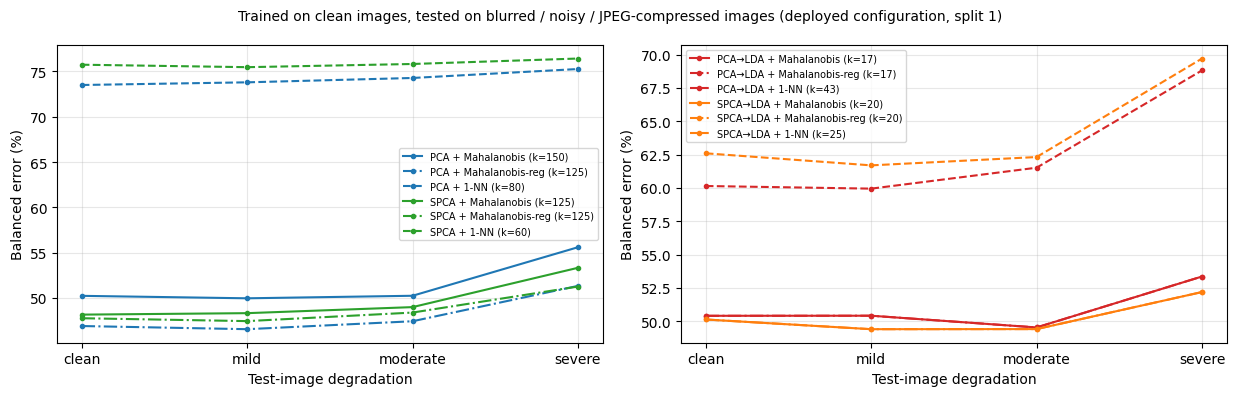

In [ ]:
def degrade_images(Xr, sigma, noise, jpeg_q, seed=0):
    rng = np.random.default_rng(seed); out = np.empty_like(Xr)
    for i, x in enumerate(Xr):
        im = x.reshape(IMG_H, IMG_W)
        if sigma > 0:
            im = gaussian_filter(im, sigma)
        if noise > 0:
            im = im + rng.normal(0.0, noise, im.shape)
        im = np.clip(im, 0.0, 1.0)
        if jpeg_q is not None:
            buf = io.BytesIO()
            Image.fromarray((im * 255).round().astype(np.uint8)).save(buf, "JPEG", quality=int(jpeg_q))
            buf.seek(0)
            im = np.asarray(Image.open(buf), dtype=np.float64) / 255.0
        out[i] = im.ravel()
    return out

Xte_levels = {name: prep(degrade_images(X_raw[TE0], s, n, q)) for name, s, n, q in DEG_LEVELS}
assert np.allclose(Xte_levels["clean"], Xte0), "the 'clean' level must reproduce the untouched test images"

dep0 = indep_results[(indep_results.seed == SEED) & (indep_results.which == "deploy")]
deg_rows = []
for method in METHODS:
    for clf in CLF_NAMES:
        r0 = dep0[(dep0.method == method) & (dep0.classifier == clf)].iloc[0]
        eta = None if pd.isna(r0.eta) else r0.eta; m = None if pd.isna(r0.m) else int(r0.m); k = int(r0.k)
        mu_, B_ = fit_map(method, Xtr0, ytr0, eta=eta, m=m)
        model = make_clf(clf, r0.gamma).fit((Xtr0 - mu_) @ B_[:, :k], ytr0)
        for name, *_ in DEG_LEVELS:
            p = model.predict((Xte_levels[name] - mu_) @ B_[:, :k])
            deg_rows.append(dict(method=method, classifier=clf, k=k, level=name,
                                 accuracy=float((p == yte0).mean()), bal_accuracy=balanced_accuracy(yte0, p)))
deg_df = pd.DataFrame(deg_rows)
deg_df.to_csv(os.path.join(OUT_DIR, "rq2_camera_degradation.csv"), index=False)
levels = [n for n, *_ in DEG_LEVELS]
deg_table = (deg_df.assign(Pipeline=deg_df.method + " + " + deg_df.classifier)
             .pivot_table(index=["Pipeline", "k"], columns="level", values="bal_accuracy")[levels] * 100).round(1).reset_index()
print("Balanced accuracy (%) at each camera-degradation level (train clean, test degraded):")
display(deg_table)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
for ax, methods in zip(axes, [["PCA", "SPCA"], ["PCA→LDA", "SPCA→LDA"]]):
    for method in methods:
        for clf in CLF_NAMES:
            d = deg_df[(deg_df.method == method) & (deg_df.classifier == clf)].set_index("level").loc[levels]
            ax.plot(range(len(levels)), 100 * (1 - d.bal_accuracy), LINES[clf], color=COLORS[method], marker="o", ms=3,
                    label=f"{method} + {clf} (k={int(d.k.iloc[0])})")
    ax.set_xticks(range(len(levels))); ax.set_xticklabels(levels)
    ax.set_xlabel("Test-image degradation"); ax.set_ylabel("Balanced error (%)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
fig.suptitle("Trained on clean images, tested on blurred / noisy / JPEG-compressed images (deployed configuration, split 1)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig4_camera_degradation.png"), dpi=300); plt.show()

## 10. RQ3: deployment
### 10a. Folded inference and fixed-point simulation
The Mahalanobis whitening is folded into one matrix (unit test: folded and unfolded predictions must agree). Integer models use symmetric per-column weight quantisation and per-image input quantisation, with float64 accumulation of integer-valued operands; a conservative bound flags possible int32 overflow. Bias and templates stay floating point and 4/6-bit packing is idealised, so this is a numerical simulation, not integer-only hardware execution.

PCA       k=150: folded vs unfolded mismatches = 0
SPCA      k=125: folded vs unfolded mismatches = 0
PCA→LDA   k= 17: folded vs unfolded mismatches = 0
SPCA→LDA  k= 20: folded vs unfolded mismatches = 0
Configurations where a 32-bit accumulator would overflow: {16: 166}


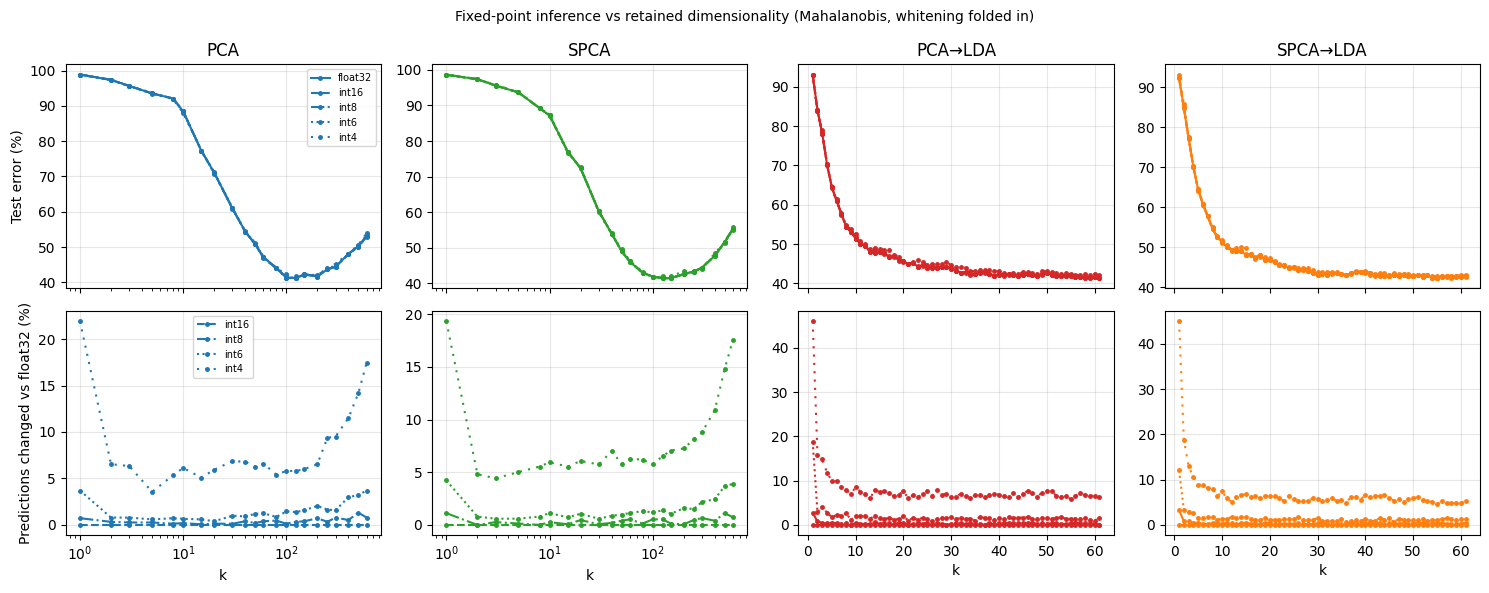

In [ ]:
def fold_mahalanobis(mu, B, k, Xa, ya, gamma=1e-6):
    clf = MinMahalanobis(gamma).fit((Xa - mu) @ B[:, :k], ya)
    A = B[:, :k] @ clf.Linv_.T
    return A, -mu @ A, clf.wmeans_, clf.classes_, clf

def quantise(M, bits, axis):
    qmax = 2 ** (bits - 1) - 1
    scale = np.abs(M).max(axis=axis, keepdims=True) / qmax
    scale[scale == 0] = 1.0
    return np.clip(np.round(M / scale), -qmax, qmax), scale

def fixed_point_predict(Xb, A, b, T, classes, bits):
    if bits >= 32:
        Z = Xb.astype(np.float32) @ A.astype(np.float32) + b.astype(np.float32)
        return classes[sqdist(Z.astype(np.float64), T).argmin(axis=1)], False
    Aq, sa = quantise(A, bits, axis=0)
    Xq, sx = quantise(Xb, bits, axis=1)
    acc = Xq @ Aq     # float64 accumulation of integer-valued operands; exact within the documented magnitude bounds
    # Conservative accumulator check: sum_i |x_i||a_i| bounds EVERY partial sum in ANY summation order,
    # so if it fits in int32, no intermediate or final overflow is possible.
    overflow32 = bool((np.abs(Xq) @ np.abs(Aq)).max() > 2**31 - 1)
    Z = acc * sx * sa + b
    return classes[sqdist(Z, T).argmin(axis=1)], overflow32

# Unit test: folded (float64) == unfolded predictions at each pipeline's deploy k
for method in METHODS:
    mu, B = MAPS0[method]; k = HP0[method]["deploy_k"]["Mahalanobis"]
    A, b, T, cls, clf = fold_mahalanobis(mu, B, k, Xtr0, ytr0)
    folded = cls[sqdist(Xte0 @ A + b, T).argmin(axis=1)]
    unfolded = clf.predict((Xte0 - mu) @ B[:, :k])
    mism = int(np.sum(folded != unfolded))
    print(f"{method:9s} k={k:3d}: folded vs unfolded mismatches = {mism}")
    assert mism <= max(1, len(yte0) // 1000), "folded inference does not match the pipeline"

q_rows = []
for method in METHODS:
    mu, B = MAPS0[method]
    for k in k_grid(method, len(ytr0), C):
        A, b, T, cls, _ = fold_mahalanobis(mu, B, k, Xtr0, ytr0)
        ref, _ = fixed_point_predict(Xte0, A, b, T, cls, 32)
        for bits in QUANT_BITS:
            p, ovf = (ref, False) if bits == 32 else fixed_point_predict(Xte0, A, b, T, cls, bits)
            q_rows.append(dict(method=method, k=k, bits=bits, accuracy=float((p == yte0).mean()), bal_accuracy=balanced_accuracy(yte0, p),
                               flip_rate=float((p != ref).mean()), int32_overflow=ovf,
                               **deploy_cost(k, C, len(ytr0), "Mahalanobis", bits)))
quant = pd.DataFrame(q_rows)
quant.to_csv(os.path.join(OUT_DIR, "rq3_quantisation.csv"), index=False)
print("Configurations where a 32-bit accumulator would overflow:",
      quant[quant.int32_overflow].groupby("bits").size().to_dict())

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex="col")
styles = dict(zip(QUANT_BITS, ["-", "--", "-.", ":", (0, (1, 3))]))
for j, method in enumerate(METHODS):
    for bits in QUANT_BITS:
        r_ = quant[(quant.method == method) & (quant.bits == bits)]
        lab = "float32" if bits == 32 else f"int{bits}"
        axes[0, j].plot(r_.k, 100 * (1 - r_.accuracy), linestyle=styles[bits], marker="o", ms=2.5,
                        color=COLORS[method], label=lab)
        if bits < 32:
            axes[1, j].plot(r_.k, 100 * r_.flip_rate, linestyle=styles[bits], marker="o", ms=2.5,
                            color=COLORS[method], label=lab)
    axes[0, j].set_title(method); axes[1, j].set_xlabel("k")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
        if "LDA" not in method: ax.set_xscale("log")
axes[0, 0].set_ylabel("Test error (%)"); axes[1, 0].set_ylabel("Predictions changed vs float32 (%)")
axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=7)
fig.suptitle("Fixed-point inference vs retained dimensionality (Mahalanobis, whitening folded in)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig5_quantisation.png"), dpi=300); plt.show()

### 10b. Accuracy vs flash, selection stability, deployed configuration
Flash covers weights, scales, bias and templates (no code). All tables use independent selection.

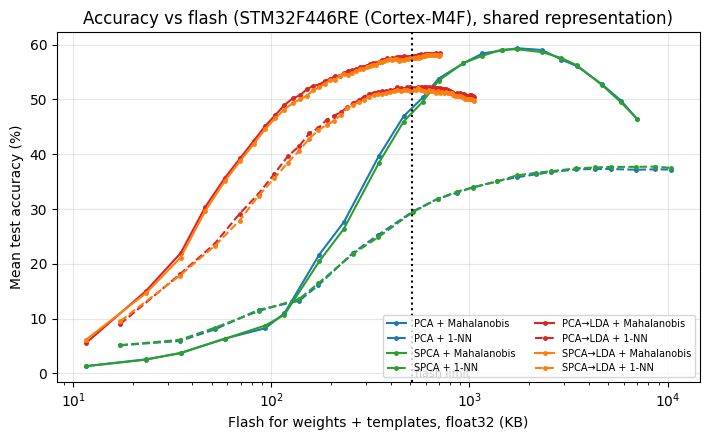

Selection policy (independent selection, across repeats):


,Pipeline,deploy k median [min–max],k IQR,freq k ≤ 3,val score (%),test bal acc @ deploy (%),test acc @ deploy (%),val→test gap (pts),θ_acc k median,test bal acc @ θ_acc (%),compression cost (pts),moderate camera: bal acc (%),"clean→moderate drop (pts, split 1)"
0,PCA + Mahalanobis,100 [40–150],53.75,0/10,47.9,49.5 ± 2.5,56.3,-1.7,112,50.0,0.4,49.8,0.0
1,PCA + Mahalanobis-reg,125 [80–300],37.50,0/10,49.8,51.4 ± 1.5,58.8,-1.6,137,51.3,-0.1,52.6,0.5
2,PCA + 1-NN,125 [80–200],43.75,0/10,26.5,27.0 ± 0.8,36.1,-0.5,200,27.5,0.6,25.7,0.8
3,SPCA + Mahalanobis,80 [60–125],53.75,0/10,48.9,49.9 ± 1.8,56.7,-1.0,100,50.3,0.4,51.0,0.8
4,SPCA + Mahalanobis-reg,100 [60–300],60.00,0/10,50.0,50.2 ± 2.2,57.1,-0.2,125,50.6,0.3,51.6,0.6
5,SPCA + 1-NN,137 [60–500],156.25,0/10,25.8,26.1 ± 0.8,36.4,-0.3,350,26.8,0.8,24.2,0.1
6,PCA→LDA + Mahalanobis,21 [17–43],7.25,0/10,48.8,49.7 ± 1.4,55.5,-0.9,39,50.4,0.7,50.5,-0.9
7,PCA→LDA + Mahalanobis-reg,21 [17–43],7.25,0/10,48.8,49.7 ± 1.4,55.5,-0.9,39,50.4,0.7,50.5,-0.9
8,PCA→LDA + 1-NN,25 [15–52],21.00,0/10,39.0,38.4 ± 2.1,50.7,0.6,40,38.4,0.0,38.5,1.4
9,SPCA→LDA + Mahalanobis,28 [19–45],15.75,0/10,49.6,49.6 ± 1.9,56.1,0.1,36,50.3,0.8,50.6,-0.7


In [ ]:
mean_rand = random_results.groupby(["method", "classifier", "k"]).agg(
    acc=("accuracy", "mean"), flash=("flash_KB", "first")).reset_index()
plt.figure(figsize=(7.2, 4.5))
for method in METHODS:
    for clf in ["Mahalanobis", "1-NN"]:
        r_ = mean_rand[(mean_rand.method == method) & (mean_rand.classifier == clf)]
        plt.plot(r_.flash, 100 * r_.acc, LINES[clf], color=COLORS[method], marker="o", ms=2.5,
                 label=f"{method} + {clf}")
plt.axvline(MCU["flash_KB"], ls=":", color="black")
plt.text(MCU["flash_KB"] * 1.04, plt.ylim()[0] + 1, "flash limit", fontsize=8)
plt.xscale("log"); plt.xlabel("Flash for weights + templates, float32 (KB)"); plt.ylabel("Mean test accuracy (%)")
plt.legend(fontsize=7, ncol=2); plt.grid(alpha=0.3); plt.title(f"Accuracy vs flash ({MCU['name']}, shared representation)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig6_accuracy_vs_flash.png"), dpi=300); plt.show()

# ---- Selection policy across repeats ----
pol_rows = []
for method in METHODS:
    for clf in CLF_NAMES:
        sel = lambda w: indep_results[(indep_results.method == method) & (indep_results.classifier == clf) & (indep_results.which == w)]
        dep, opt = sel("deploy"), sel("acc")
        dg = deg_df[(deg_df.method == method) & (deg_df.classifier == clf)].set_index("level")
        pol_rows.append({
            "Pipeline": f"{method} + {clf}",
            "deploy k median [min–max]": f"{int(dep.k.median())} [{dep.k.min()}–{dep.k.max()}]",
            "k IQR": float(dep.k.quantile(0.75) - dep.k.quantile(0.25)),
            "freq k ≤ 3": f"{int((dep.k <= 3).sum())}/{len(dep)}",
            "val score (%)": round(100 * dep.val_acc.mean(), 1),
            "test bal acc @ deploy (%)": f"{100*dep.test_bal_acc.mean():.1f} ± {100*dep.test_bal_acc.std():.1f}",
            "test acc @ deploy (%)": round(100 * dep.test_acc.mean(), 1),
            "val→test gap (pts)": round(100 * (dep.val_acc - dep.test_bal_acc).mean(), 1),
            "θ_acc k median": int(opt.k.median()),
            "test bal acc @ θ_acc (%)": round(100 * opt.test_bal_acc.mean(), 1),
            "compression cost (pts)": round(100 * (opt.test_bal_acc.values - dep.test_bal_acc.values).mean(), 1),
            f"{DEG_REF_LEVEL} camera: bal acc (%)": round(100 * dg.loc[DEG_REF_LEVEL, "bal_accuracy"], 1),
            f"clean→{DEG_REF_LEVEL} drop (pts, split 1)": round(100 * (dg.loc["clean", "bal_accuracy"] - dg.loc[DEG_REF_LEVEL, "bal_accuracy"]), 1)})
policy_table = pd.DataFrame(pol_rows)
policy_table.to_csv(os.path.join(OUT_DIR, "rq3_selection_policy.csv"), index=False)
print("Selection policy (independent selection, across repeats):"); display(policy_table)

# ---- Illustrative deployed configuration (split 1) ----
dep_rows = []
for method in METHODS:
    for clf in CLF_NAMES:
        r0 = indep_results[(indep_results.seed == SEED) & (indep_results.method == method) &
                           (indep_results.classifier == clf) & (indep_results.which == "deploy")].iloc[0]
        eta, m, g, k = r0.eta, r0.m, r0.gamma, int(r0.k)
        eta = None if pd.isna(eta) else eta; m = None if pd.isna(m) else int(m)
        q8 = "—"
        if clf != "1-NN":
            mu, B = fit_map(method, Xtr0, ytr0, eta=eta, m=m)
            A, b, T, cls, _ = fold_mahalanobis(mu, B, k, Xtr0, ytr0, g if clf == "Mahalanobis-reg" else 1e-6)
            p8, _ = fixed_point_predict(Xte0, A, b, T, cls, 8)
            q8 = round(100 * balanced_accuracy(yte0, p8), 1)
        c32, c8 = deploy_cost(k, C, N_TR, clf, 32), deploy_cost(k, C, N_TR, clf, 8)
        dep_rows.append({
            "Pipeline": f"{method} + {clf}", "η": eta, "m": m,
            "γ": g if clf == "Mahalanobis-reg" else "—", "k": k,
            "val score (%)": round(100 * r0.val_acc, 1), "test acc (%)": round(100 * r0.test_acc, 1),
            "test bal acc (%)": round(100 * r0.test_bal_acc, 1), "int8 bal acc (%)": q8,
            "flash KB fp32 / int8": f"{c32['flash_KB']:.0f} / {c8['flash_KB']:.0f}",
            "RAM KB fp32 / int8": f"{c32['ram_KB']:.1f} / {c8['ram_KB']:.1f}",
            "ops": int(c32["ops"]),
            "est. ms fp32 / int8": f"{c32['est_latency_ms']:.2f} / {c8['est_latency_ms']:.2f}",
            "fits flash fp32 / int8": f"{c32['flash_KB'] <= MCU['flash_KB']} / {c8['flash_KB'] <= MCU['flash_KB']}"})
deploy_table = pd.DataFrame(dep_rows)
deploy_table.to_csv(os.path.join(OUT_DIR, "rq3_deployed_configuration_split1.csv"), index=False)
print("Illustrative deployed configuration (split 1; every number in a row is the same model):")
display(deploy_table)


## Notes
Closed-set identification on a filtered, demographically skewed LFW subset. Latency is estimated, nothing was measured on hardware, the degradation test is synthetic, and all significance tests are exploratory.